# Projeto AM-NS 2026-2 - Equipe 8
Agrupamento e redução de dimensionalidade na base Iris.

Algoritmos da Equipe 8: K-means, Fuzzy K-means, Kernel Fuzzy K-means, K-medoids (euclidiana), Misturas EM, UPGMA (city-block) e DBSCAN.
Questão 2: PCA, Kernel PCA, t-SNE e UMAP.

## 0. Instalação e dados

In [1]:
# --no-deps para o pip não trocar o numpy que já vem carregado no Colab
!pip install -q --no-deps fuzzy-c-means kmedoids
!pip install -q umap-learn pynndescent tqdm typer pydantic
# se der erro de numpy/pandas depois, use Ambiente de execução > Reiniciar sessão e rode a partir da próxima célula

In [2]:
%%writefile iris.data
5.1,3.5,1.4,0.2,Iris-setosa
4.9,3.0,1.4,0.2,Iris-setosa
4.7,3.2,1.3,0.2,Iris-setosa
4.6,3.1,1.5,0.2,Iris-setosa
5.0,3.6,1.4,0.2,Iris-setosa
5.4,3.9,1.7,0.4,Iris-setosa
4.6,3.4,1.4,0.3,Iris-setosa
5.0,3.4,1.5,0.2,Iris-setosa
4.4,2.9,1.4,0.2,Iris-setosa
4.9,3.1,1.5,0.1,Iris-setosa
5.4,3.7,1.5,0.2,Iris-setosa
4.8,3.4,1.6,0.2,Iris-setosa
4.8,3.0,1.4,0.1,Iris-setosa
4.3,3.0,1.1,0.1,Iris-setosa
5.8,4.0,1.2,0.2,Iris-setosa
5.7,4.4,1.5,0.4,Iris-setosa
5.4,3.9,1.3,0.4,Iris-setosa
5.1,3.5,1.4,0.3,Iris-setosa
5.7,3.8,1.7,0.3,Iris-setosa
5.1,3.8,1.5,0.3,Iris-setosa
5.4,3.4,1.7,0.2,Iris-setosa
5.1,3.7,1.5,0.4,Iris-setosa
4.6,3.6,1.0,0.2,Iris-setosa
5.1,3.3,1.7,0.5,Iris-setosa
4.8,3.4,1.9,0.2,Iris-setosa
5.0,3.0,1.6,0.2,Iris-setosa
5.0,3.4,1.6,0.4,Iris-setosa
5.2,3.5,1.5,0.2,Iris-setosa
5.2,3.4,1.4,0.2,Iris-setosa
4.7,3.2,1.6,0.2,Iris-setosa
4.8,3.1,1.6,0.2,Iris-setosa
5.4,3.4,1.5,0.4,Iris-setosa
5.2,4.1,1.5,0.1,Iris-setosa
5.5,4.2,1.4,0.2,Iris-setosa
4.9,3.1,1.5,0.1,Iris-setosa
5.0,3.2,1.2,0.2,Iris-setosa
5.5,3.5,1.3,0.2,Iris-setosa
4.9,3.1,1.5,0.1,Iris-setosa
4.4,3.0,1.3,0.2,Iris-setosa
5.1,3.4,1.5,0.2,Iris-setosa
5.0,3.5,1.3,0.3,Iris-setosa
4.5,2.3,1.3,0.3,Iris-setosa
4.4,3.2,1.3,0.2,Iris-setosa
5.0,3.5,1.6,0.6,Iris-setosa
5.1,3.8,1.9,0.4,Iris-setosa
4.8,3.0,1.4,0.3,Iris-setosa
5.1,3.8,1.6,0.2,Iris-setosa
4.6,3.2,1.4,0.2,Iris-setosa
5.3,3.7,1.5,0.2,Iris-setosa
5.0,3.3,1.4,0.2,Iris-setosa
7.0,3.2,4.7,1.4,Iris-versicolor
6.4,3.2,4.5,1.5,Iris-versicolor
6.9,3.1,4.9,1.5,Iris-versicolor
5.5,2.3,4.0,1.3,Iris-versicolor
6.5,2.8,4.6,1.5,Iris-versicolor
5.7,2.8,4.5,1.3,Iris-versicolor
6.3,3.3,4.7,1.6,Iris-versicolor
4.9,2.4,3.3,1.0,Iris-versicolor
6.6,2.9,4.6,1.3,Iris-versicolor
5.2,2.7,3.9,1.4,Iris-versicolor
5.0,2.0,3.5,1.0,Iris-versicolor
5.9,3.0,4.2,1.5,Iris-versicolor
6.0,2.2,4.0,1.0,Iris-versicolor
6.1,2.9,4.7,1.4,Iris-versicolor
5.6,2.9,3.6,1.3,Iris-versicolor
6.7,3.1,4.4,1.4,Iris-versicolor
5.6,3.0,4.5,1.5,Iris-versicolor
5.8,2.7,4.1,1.0,Iris-versicolor
6.2,2.2,4.5,1.5,Iris-versicolor
5.6,2.5,3.9,1.1,Iris-versicolor
5.9,3.2,4.8,1.8,Iris-versicolor
6.1,2.8,4.0,1.3,Iris-versicolor
6.3,2.5,4.9,1.5,Iris-versicolor
6.1,2.8,4.7,1.2,Iris-versicolor
6.4,2.9,4.3,1.3,Iris-versicolor
6.6,3.0,4.4,1.4,Iris-versicolor
6.8,2.8,4.8,1.4,Iris-versicolor
6.7,3.0,5.0,1.7,Iris-versicolor
6.0,2.9,4.5,1.5,Iris-versicolor
5.7,2.6,3.5,1.0,Iris-versicolor
5.5,2.4,3.8,1.1,Iris-versicolor
5.5,2.4,3.7,1.0,Iris-versicolor
5.8,2.7,3.9,1.2,Iris-versicolor
6.0,2.7,5.1,1.6,Iris-versicolor
5.4,3.0,4.5,1.5,Iris-versicolor
6.0,3.4,4.5,1.6,Iris-versicolor
6.7,3.1,4.7,1.5,Iris-versicolor
6.3,2.3,4.4,1.3,Iris-versicolor
5.6,3.0,4.1,1.3,Iris-versicolor
5.5,2.5,4.0,1.3,Iris-versicolor
5.5,2.6,4.4,1.2,Iris-versicolor
6.1,3.0,4.6,1.4,Iris-versicolor
5.8,2.6,4.0,1.2,Iris-versicolor
5.0,2.3,3.3,1.0,Iris-versicolor
5.6,2.7,4.2,1.3,Iris-versicolor
5.7,3.0,4.2,1.2,Iris-versicolor
5.7,2.9,4.2,1.3,Iris-versicolor
6.2,2.9,4.3,1.3,Iris-versicolor
5.1,2.5,3.0,1.1,Iris-versicolor
5.7,2.8,4.1,1.3,Iris-versicolor
6.3,3.3,6.0,2.5,Iris-virginica
5.8,2.7,5.1,1.9,Iris-virginica
7.1,3.0,5.9,2.1,Iris-virginica
6.3,2.9,5.6,1.8,Iris-virginica
6.5,3.0,5.8,2.2,Iris-virginica
7.6,3.0,6.6,2.1,Iris-virginica
4.9,2.5,4.5,1.7,Iris-virginica
7.3,2.9,6.3,1.8,Iris-virginica
6.7,2.5,5.8,1.8,Iris-virginica
7.2,3.6,6.1,2.5,Iris-virginica
6.5,3.2,5.1,2.0,Iris-virginica
6.4,2.7,5.3,1.9,Iris-virginica
6.8,3.0,5.5,2.1,Iris-virginica
5.7,2.5,5.0,2.0,Iris-virginica
5.8,2.8,5.1,2.4,Iris-virginica
6.4,3.2,5.3,2.3,Iris-virginica
6.5,3.0,5.5,1.8,Iris-virginica
7.7,3.8,6.7,2.2,Iris-virginica
7.7,2.6,6.9,2.3,Iris-virginica
6.0,2.2,5.0,1.5,Iris-virginica
6.9,3.2,5.7,2.3,Iris-virginica
5.6,2.8,4.9,2.0,Iris-virginica
7.7,2.8,6.7,2.0,Iris-virginica
6.3,2.7,4.9,1.8,Iris-virginica
6.7,3.3,5.7,2.1,Iris-virginica
7.2,3.2,6.0,1.8,Iris-virginica
6.2,2.8,4.8,1.8,Iris-virginica
6.1,3.0,4.9,1.8,Iris-virginica
6.4,2.8,5.6,2.1,Iris-virginica
7.2,3.0,5.8,1.6,Iris-virginica
7.4,2.8,6.1,1.9,Iris-virginica
7.9,3.8,6.4,2.0,Iris-virginica
6.4,2.8,5.6,2.2,Iris-virginica
6.3,2.8,5.1,1.5,Iris-virginica
6.1,2.6,5.6,1.4,Iris-virginica
7.7,3.0,6.1,2.3,Iris-virginica
6.3,3.4,5.6,2.4,Iris-virginica
6.4,3.1,5.5,1.8,Iris-virginica
6.0,3.0,4.8,1.8,Iris-virginica
6.9,3.1,5.4,2.1,Iris-virginica
6.7,3.1,5.6,2.4,Iris-virginica
6.9,3.1,5.1,2.3,Iris-virginica
5.8,2.7,5.1,1.9,Iris-virginica
6.8,3.2,5.9,2.3,Iris-virginica
6.7,3.3,5.7,2.5,Iris-virginica
6.7,3.0,5.2,2.3,Iris-virginica
6.3,2.5,5.0,1.9,Iris-virginica
6.5,3.0,5.2,2.0,Iris-virginica
6.2,3.4,5.4,2.3,Iris-virginica
5.9,3.0,5.1,1.8,Iris-virginica

Writing iris.data


## 1. Imports e configurações

In [3]:
import sys

# o UMAP tenta importar TensorFlow/JAX por causa da versão paramétrica, que não usamos.
# Bloquear o import evita conflito de versão do numpy no Colab.
sys.modules["tensorflow"] = None

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dataclasses import dataclass, field
from IPython.display import display
from fcmeans import FCM, KFCM
from kmedoids import pam
from scipy.cluster.hierarchy import cut_tree, dendrogram, linkage
from scipy.spatial.distance import cdist, pdist
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from umap import UMAP

sns.set_theme(style="whitegrid")

PADRONIZAR = True        # padroniza os 4 atributos (média 0, desvio 1)
VALORES_K = range(1, 6)
SEED_INICIAL = 42        # 10 sementes por k: 42 até 51
EPS_DBSCAN, MIN_SAMPLES_DBSCAN = 0.8, 5
GAMMA_KERNEL = 0.25      # usado no Kernel Fuzzy K-means e na Kernel PCA
PERPLEXIDADE, VIZINHOS_UMAP, MIN_DIST_UMAP, SEED_Q2 = 30, 15, 0.1, 42

## 2. Resultados, registro dos algoritmos e métricas

In [4]:
@dataclass
class Resultado:
    algoritmo: str
    tipo: str
    rotulos: np.ndarray
    objetivo: float = None
    parametros: dict = field(default_factory=dict)
    centros: np.ndarray = None
    pertinencias: np.ndarray = None    # só nos fuzzy
    probabilidades: np.ndarray = None  # só no EM
    hierarquia: np.ndarray = None      # matriz de ligações do UPGMA
    ruido: int = 0


# guarda cada algoritmo com o número de execuções e se o objetivo é min ou max
REGISTRO = {}

def algoritmo(nome, execucoes=10, objetivo="minimizar"):
    def deco(f):
        REGISTRO[nome] = {"funcao": f, "execucoes": execucoes, "objetivo": objetivo}
        return f
    return deco


def executar_todas_por_k(nome, X, valores_k=VALORES_K, seed_inicial=SEED_INICIAL):
    # roda as 10 sementes seguidas para cada k
    reg = REGISTRO[nome]
    return {k: [reg["funcao"](X, k=k, seed=seed_inicial + t) for t in range(reg["execucoes"])]
            for k in valores_k}


def selecionar_melhores_por_k(nome, todas):
    # fica com a melhor semente de cada k, olhando só o objetivo
    seletor = max if REGISTRO[nome]["objetivo"] == "maximizar" else min
    return {k: seletor(r, key=lambda x: x.objetivo) for k, r in todas.items()}


def calcular_silhueta(X, rotulos, ignorar_ruido=False):
    X, lab = np.asarray(X, float), np.asarray(rotulos)
    if ignorar_ruido:
        m = lab != -1
        X, lab = X[m], lab[m]
    n = len(np.unique(lab))
    if len(X) < 2 or n < 2 or n >= len(X):
        return float("nan")   # com k=1 a silhueta não existe
    return float(silhouette_score(X, lab, metric="euclidean"))


def selecionar_k_por_silhueta(X, resultados):
    sil = {k: calcular_silhueta(X, r.rotulos) for k, r in resultados.items()}
    validos = {k: s for k, s in sil.items() if not np.isnan(s)}
    return max(validos, key=validos.get), sil


def calcular_ari(y_true, y_pred):
    return float(adjusted_rand_score(y_true, y_pred))


def plotar_silhueta(ax, nome, sil, k_estrela):
    ks = [k for k in sorted(sil) if not np.isnan(sil[k])]
    ax.plot(ks, [sil[k] for k in ks], marker="o", lw=2)
    ax.axvline(k_estrela, color="crimson", ls="--", label=f"k* = {k_estrela}")
    ax.scatter(k_estrela, sil[k_estrela], color="crimson", s=70, zorder=3)
    ax.set(title=f"Sil x k - {nome}", xlabel="k", ylabel="Silhueta média", xticks=sorted(sil))
    ax.legend()

## 3. Os algoritmos
- K-means: `n_init=1` e init aleatório. As 10 execuções são feitas por fora, trocando a semente. Objetivo: inércia (minimizar).
- Fuzzy e Kernel Fuzzy K-means: m = 2, 300 iterações, tol 1e-5. O objetivo (soma de u² · d²) é calculado na mão. O rótulo crisp é o argmax da pertinência.
- K-medoids: PAM com distância euclidiana (para k=1 busca todos os pontos).
- EM (GMM): covariância completa. O objetivo é a log-verossimilhança total (maximizar). O rótulo crisp é o argmax da probabilidade.
- UPGMA: ligação média com distância city-block. Uma hierarquia só, cortada em k=1..5.
- DBSCAN: euclidiana, eps=0,8 e min_samples=5.

In [5]:
def _validar(data, k):
    X = np.asarray(data, float)
    assert X.ndim == 2 and np.isfinite(X).all() and 1 <= k <= len(X)
    return X


@algoritmo("k-means")
def k_means(data, k, seed):
    X = _validar(data, k)
    m = KMeans(n_clusters=k, n_init=1, init="random", random_state=seed).fit(X)
    return Resultado("k-means", "crisp", m.labels_.copy(), float(m.inertia_),
                     {"k": k, "seed": seed}, m.cluster_centers_.copy())


def _fuzzy(data, k, seed, gamma=None):
    X = _validar(data, k)
    op = dict(n_clusters=k, m=2.0, max_iter=300, error=1e-5, random_state=seed)
    modelo = FCM(**op) if gamma is None else KFCM(**op, gamma=gamma)
    modelo.fit(X)
    centros, u = modelo.centers.copy(), modelo.u.copy()
    d2 = np.sum((X[:, None, :] - centros[None, :, :]) ** 2, axis=2)
    nome = "fuzzy-k-means"
    if gamma is not None:
        nome = "kernel-fuzzy-k-means"
        d2 = 2 * (1 - np.exp(-float(modelo.gamma_) * d2))   # distância no espaço do kernel RBF
    return Resultado(nome, "fuzzy", np.argmax(u, axis=1), float(np.sum(u**2 * d2)),
                     {"k": k, "seed": seed, "m": 2.0}, centros, pertinencias=u)


@algoritmo("fuzzy-k-means")
def fuzzy_k_means(data, k, seed):
    return _fuzzy(data, k, seed)


@algoritmo("kernel-fuzzy-k-means")
def kernel_fuzzy_k_means(data, k, seed):
    return _fuzzy(data, k, seed, gamma=GAMMA_KERNEL)


@algoritmo("k-medoids")
def k_medoids(data, k, seed):
    X = _validar(data, k)
    D = cdist(X, X, metric="euclidean")
    if k == 1:
        idx = np.array([np.argmin(D.sum(axis=0))])
        rot, obj = np.zeros(len(X), dtype=int), float(D[:, idx[0]].sum())
    else:
        m = pam(D, k, init="random", max_iter=300, random_state=seed)
        idx, rot, obj = np.asarray(m.medoids, int), m.labels.copy(), float(m.loss)
    return Resultado("k-medoids", "crisp", rot, obj,
                     {"k": k, "seed": seed, "medoids": idx.tolist()}, X[idx].copy())


@algoritmo("gaussian-mixture", objetivo="maximizar")
def gaussian_mixture(data, k, seed):
    X = _validar(data, k)
    m = GaussianMixture(n_components=k, covariance_type="full", random_state=seed, tol=1e-5,
                        reg_covar=1e-6, n_init=1, init_params="random_from_data").fit(X)
    p = m.predict_proba(X)
    return Resultado("gaussian-mixture", "probabilistico", np.argmax(p, axis=1),
                     float(m.score(X) * len(X)), {"k": k, "seed": seed, "converged": m.converged_},
                     np.array(m.means_, copy=True), probabilidades=p)


def upgma(data, valores_k=(1, 2, 3, 4, 5)):
    X = _validar(data, 1)
    H = linkage(pdist(X, metric="cityblock"), method="average")   # UPGMA com Manhattan
    cortes = cut_tree(H, n_clusters=list(valores_k))
    return {k: Resultado("upgma", "hierarquico", cortes[:, i].copy(),
                         parametros={"k": k, "metric": "manhattan", "linkage": "average"},
                         hierarquia=H.copy()) for i, k in enumerate(valores_k)}


def dbscan(data, eps=0.5, min_samples=5):
    X = np.asarray(data, float)
    rot = DBSCAN(eps=eps, min_samples=min_samples, metric="euclidean").fit_predict(X)
    return Resultado("dbscan", "densidade", rot, None,
                     {"eps": eps, "min_samples": min_samples}, ruido=int(np.sum(rot == -1)))

## 4. Carregando a Iris

In [6]:
cols = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
df = pd.read_csv("iris.data", header=None, names=cols).dropna(how="all")
assert df.shape[0] == 150

ATRIBUTOS = cols[:-1]
X = df[ATRIBUTOS].to_numpy(float)
y = df["species"].to_numpy()
if PADRONIZAR:
    X = StandardScaler().fit_transform(X)

print(df.shape, df["species"].value_counts().to_dict())
df.head()

(150, 5) {'Iris-setosa': 50, 'Iris-versicolor': 50, 'Iris-virginica': 50}


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## 5. Questão 1
Algoritmos particionais: 5 algoritmos x 5 valores de k x 10 sementes = 250 ajustes. Somando a hierarquia do UPGMA (5 cortes) e o DBSCAN, são 252 execuções principais.

In [7]:
NOMES_PARTICIONAIS = ["k-means", "fuzzy-k-means", "kernel-fuzzy-k-means", "k-medoids", "gaussian-mixture"]

todas, melhores = {}, {}
for nome in NOMES_PARTICIONAIS:
    print(f"Executando {nome} (50 ajustes)...")
    todas[nome] = executar_todas_por_k(nome, X)
    melhores[nome] = selecionar_melhores_por_k(nome, todas[nome])

print("Executando upgma (1 hierarquia, 5 cortes)...")
res_upgma = upgma(X, VALORES_K)
melhores["upgma"] = res_upgma

print("Executando dbscan...")
res_dbscan = dbscan(X, EPS_DBSCAN, MIN_SAMPLES_DBSCAN)

Executando k-means (50 ajustes)...
Executando fuzzy-k-means (50 ajustes)...
Executando kernel-fuzzy-k-means (50 ajustes)...
Executando k-medoids (50 ajustes)...
Executando gaussian-mixture (50 ajustes)...
Executando upgma (1 hierarquia, 5 cortes)...
Executando dbscan...


### 5.1 Silhueta x k e escolha do k*

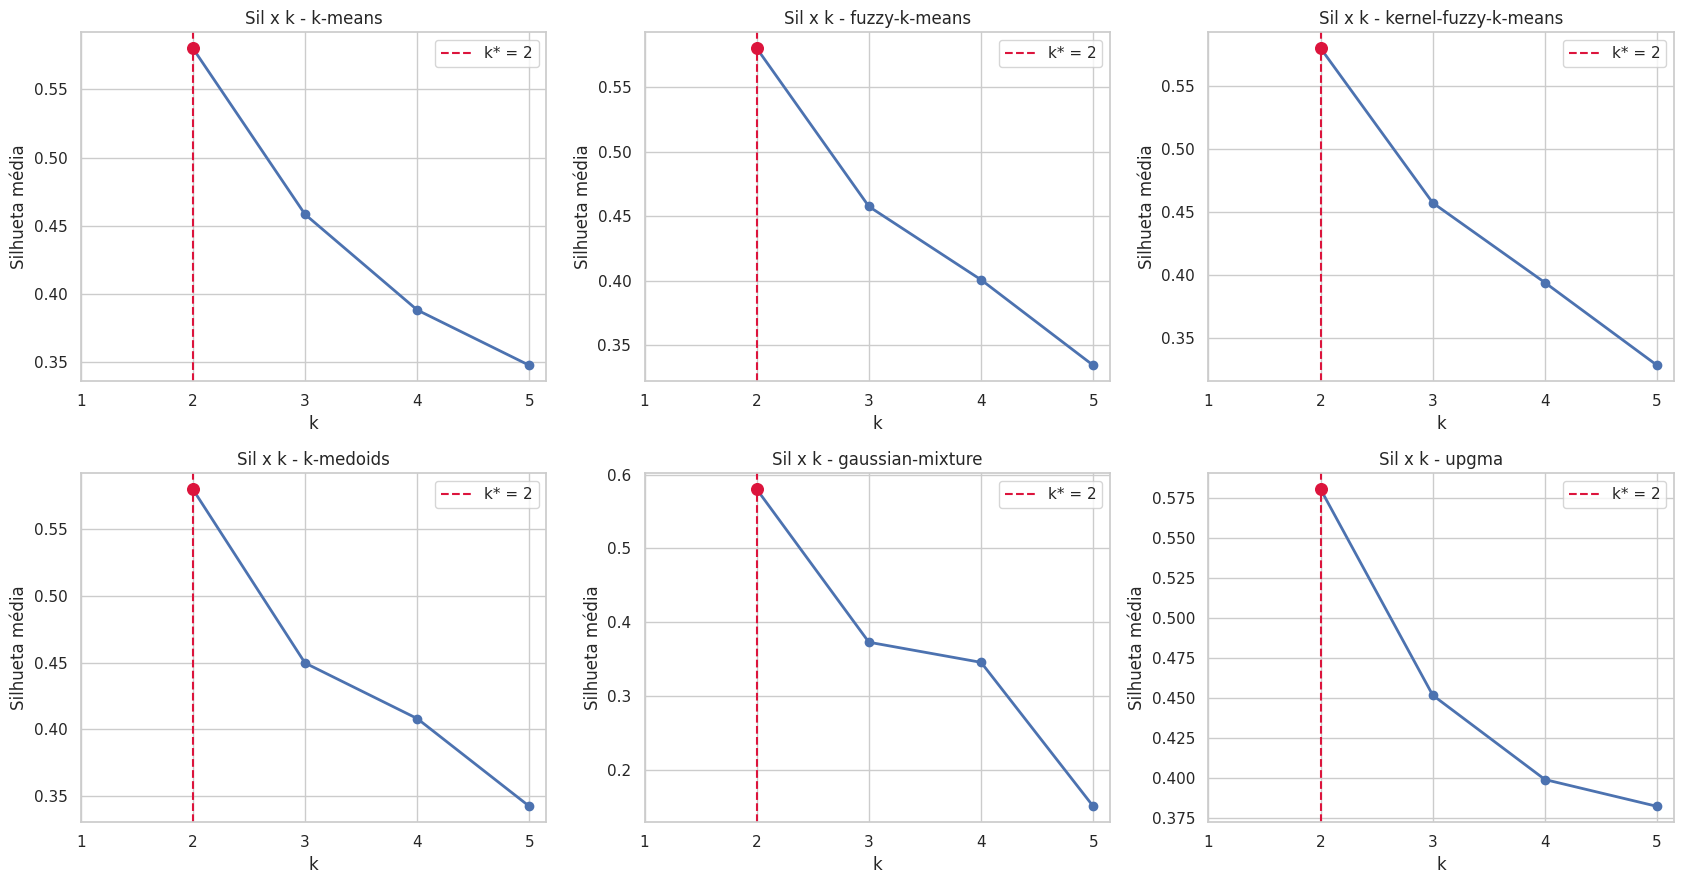

,k=1,k=2,k=3,k=4,k=5
k-means,NaN,0.5802,0.4584,0.3883,0.3477
fuzzy-k-means,NaN,0.5802,0.4574,0.4006,0.3342
kernel-fuzzy-k-means,NaN,0.5802,0.4574,0.3941,0.3285
k-medoids,NaN,0.5802,0.4497,0.4080,0.3421
gaussian-mixture,NaN,0.5802,0.3728,0.3455,0.1503
upgma,NaN,0.5802,0.4517,0.3991,0.3824


In [8]:
escolha = {}
fig, axs = plt.subplots(2, 3, figsize=(17, 9))
for ax, (nome, res) in zip(axs.ravel(), melhores.items()):
    k_est, sil = selecionar_k_por_silhueta(X, res)
    escolha[nome] = (k_est, sil)
    plotar_silhueta(ax, nome, sil, k_est)
plt.tight_layout()
plt.show()

tab_sil = pd.DataFrame({n: s for n, (k, s) in escolha.items()}).T
tab_sil.columns = [f"k={k}" for k in tab_sil.columns]
display(tab_sil.round(4))

### 5.2 Dendrograma do UPGMA (city-block)

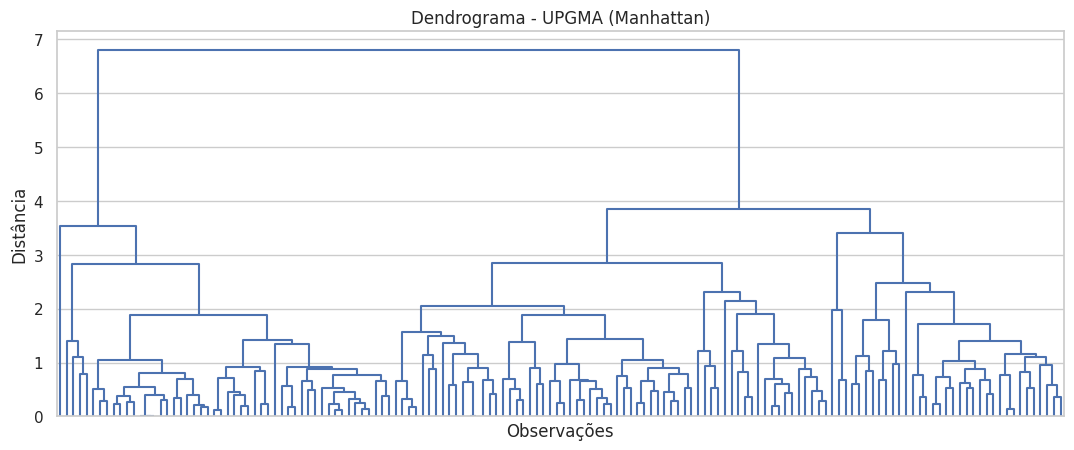

In [9]:
fig, ax = plt.subplots(figsize=(13, 5))
dendrogram(res_upgma[2].hierarquia, no_labels=True, ax=ax, color_threshold=0)
ax.set(title="Dendrograma - UPGMA (Manhattan)", xlabel="Observações", ylabel="Distância")
plt.show()

### 5.3 Resumo: k*, silhueta e ARI (partição crisp com k*)

In [10]:
linhas = []
for nome, res in melhores.items():
    k_est, sil = escolha[nome]
    linhas.append({"Algoritmo": nome, "k*": k_est, "Silhueta": sil[k_est],
                   "ARI": calcular_ari(y, res[k_est].rotulos), "Ruído": 0})

linhas.append({"Algoritmo": "dbscan", "k*": f"auto ({len(set(res_dbscan.rotulos) - {-1})} grupos)",
               "Silhueta": calcular_silhueta(X, res_dbscan.rotulos, ignorar_ruido=True),
               "ARI": calcular_ari(y, res_dbscan.rotulos), "Ruído": res_dbscan.ruido})

resumo = pd.DataFrame(linhas)
display(resumo.round(4))

# ARI para cada k, só para comentar. O k continua sendo escolhido pela silhueta.
ari_k = pd.DataFrame({n: {f"k={k}": calcular_ari(y, r.rotulos) for k, r in res.items()}
                      for n, res in melhores.items()}).T
print("ARI por k:")
display(ari_k.round(4))

,Algoritmo,k*,Silhueta,ARI,Ruído
0,k-means,2,0.5802,0.5681,0
1,fuzzy-k-means,2,0.5802,0.5681,0
2,kernel-fuzzy-k-means,2,0.5802,0.5681,0
3,k-medoids,2,0.5802,0.5681,0
4,gaussian-mixture,2,0.5802,0.5681,0
5,upgma,2,0.5802,0.5681,0
6,dbscan,auto (2 grupos),0.5963,0.5518,4


ARI por k:


,k=1,k=2,k=3,k=4,k=5
k-means,0.0,0.5681,0.6101,0.4428,0.4191
fuzzy-k-means,0.0,0.5681,0.6303,0.5877,0.4324
kernel-fuzzy-k-means,0.0,0.5681,0.6303,0.5888,0.4526
k-medoids,0.0,0.5681,0.6765,0.5869,0.4440
gaussian-mixture,0.0,0.5681,0.9039,0.8335,0.7268
upgma,0.0,0.5681,0.7184,0.7076,0.6875


### 5.4 Tabelas de contingência (espécie x grupo)

In [11]:
for nome, res in melhores.items():
    k_est = escolha[nome][0]
    print(f"--- {nome} (k*={k_est}) ---")
    display(pd.crosstab(pd.Series(y, name="espécie"), pd.Series(res[k_est].rotulos, name="grupo")))

print("--- dbscan (-1 = ruído) ---")
display(pd.crosstab(pd.Series(y, name="espécie"), pd.Series(res_dbscan.rotulos, name="grupo")))

# o EM com k=3 separa bem as espécies, vale comentar
print("--- gaussian-mixture com k=3 ---")
display(pd.crosstab(pd.Series(y, name="espécie"),
                    pd.Series(melhores["gaussian-mixture"][3].rotulos, name="grupo")))

--- k-means (k*=2) ---


grupo,0,1
espécie,,
Iris-setosa,50,0
Iris-versicolor,0,50
Iris-virginica,0,50


--- fuzzy-k-means (k*=2) ---


grupo,0,1
espécie,,
Iris-setosa,0,50
Iris-versicolor,50,0
Iris-virginica,50,0


--- kernel-fuzzy-k-means (k*=2) ---


grupo,0,1
espécie,,
Iris-setosa,50,0
Iris-versicolor,0,50
Iris-virginica,0,50


... (6 outputs left out)

--- dbscan (-1 = ruído) ---


grupo,-1,0,1
espécie,,,
Iris-setosa,1,49,0
Iris-versicolor,0,0,50
Iris-virginica,3,0,47


--- gaussian-mixture com k=3 ---


grupo,0,1,2
espécie,,,
Iris-setosa,50,0,0
Iris-versicolor,0,45,5
Iris-virginica,0,0,50


### 5.5 Função objetivo nas 10 sementes (k = 3)

In [12]:
obj = pd.DataFrame({n: [r.objetivo for r in todas[n][3]] for n in NOMES_PARTICIONAIS},
                   index=[f"seed {SEED_INICIAL+i}" for i in range(10)])
display(obj.round(4))
display(obj.agg(["min", "max"]).round(4))

,k-means,fuzzy-k-means,kernel-fuzzy-k-means,k-medoids,gaussian-mixture
seed 42,141.1542,101.2222,32.7858,132.3408,-301.6346
seed 43,192.0372,101.2222,32.7858,131.2703,-315.2023
seed 44,141.1542,101.2222,32.7858,131.2703,-292.0197
seed 45,141.1415,101.2222,32.7858,132.3408,-312.5885
seed 46,141.1542,101.2222,32.7858,132.3408,-292.0197
seed 47,141.1542,101.2222,32.7858,131.2703,-310.7042
seed 48,192.0372,101.2222,32.7858,132.3408,-292.0196
seed 49,142.1106,101.2222,32.7858,131.2703,-318.3884
seed 50,192.0372,101.2222,32.7858,131.2703,-292.0197
seed 51,140.9684,101.2222,32.7858,131.2703,-298.4030


,k-means,fuzzy-k-means,kernel-fuzzy-k-means,k-medoids,gaussian-mixture
min,140.9684,101.2222,32.7858,131.2703,-318.3884
max,192.0372,101.2222,32.7858,132.3408,-292.0196


## 6. Questão 2 - PCA, Kernel PCA, t-SNE e UMAP
Todas as técnicas usam a mesma matriz padronizada com os 4 atributos. Para cada uma mostramos as saídas, o gráfico 2D e a trustworthiness (quanto dos 10 vizinhos mais próximos foi preservado, de 0 a 1).

In [13]:
def scatter2d(Z, titulo, xl="Componente 1", yl="Componente 2"):
    fig, ax = plt.subplots(figsize=(8, 5.5))
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y, style=y, s=55, ax=ax)
    ax.set(title=titulo, xlabel=xl, ylabel=yl)
    ax.legend(title="Espécie", fontsize=8)
    plt.show()

trust = {}

### 6.1 PCA

,Autovalor,Variância (%),Acumulada (%),Valor singular
PC1,2.9304,72.7705,72.7705,20.8955
PC2,0.9274,23.0305,95.8010,11.7551
PC3,0.1483,3.6838,99.4848,4.7014
PC4,0.0207,0.5152,100.0000,1.7582


Componentes (autovetores):


,PC1,PC2,PC3,PC4
sepal_length,0.5224,0.3723,0.7210,-0.2620
sepal_width,-0.2634,0.9256,-0.2420,0.1241
petal_length,0.5813,0.0211,-0.1409,0.8012
petal_width,0.5656,0.0654,-0.6338,-0.5235


Loadings (autovetor x raiz do autovalor):


,PC1,PC2,PC3,PC4
sepal_length,0.8942,0.3585,0.2777,-0.0377
sepal_width,-0.4508,0.8913,-0.0932,0.0179
petal_length,0.9950,0.0203,-0.0543,0.1154
petal_width,0.9682,0.0630,-0.2441,-0.0754


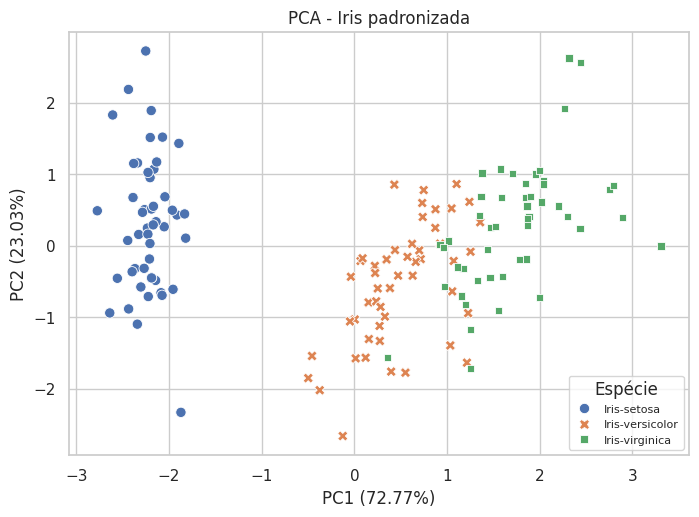

In [14]:
pca = PCA(n_components=4, svd_solver="full")
Z_pca = pca.fit_transform(X)
cp = [f"PC{i+1}" for i in range(4)]

saida_pca = pd.DataFrame({"Autovalor": pca.explained_variance_,
                          "Variância (%)": 100 * pca.explained_variance_ratio_,
                          "Acumulada (%)": 100 * np.cumsum(pca.explained_variance_ratio_),
                          "Valor singular": pca.singular_values_}, index=cp)
display(saida_pca.round(4))

print("Componentes (autovetores):")
display(pd.DataFrame(pca.components_.T, index=ATRIBUTOS, columns=cp).round(4))

print("Loadings (autovetor x raiz do autovalor):")
display(pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_), index=ATRIBUTOS, columns=cp).round(4))

trust["PCA"] = trustworthiness(X, Z_pca[:, :2], n_neighbors=10)
scatter2d(Z_pca, "PCA - Iris padronizada",
          f"PC1 ({pca.explained_variance_ratio_[0]:.2%})", f"PC2 ({pca.explained_variance_ratio_[1]:.2%})")

### 6.2 Kernel PCA (RBF)

Autovalores do kernel centralizado: [39.1321 17.7924]
Parâmetros: {'alpha': 1.0, 'coef0': 1, 'copy_X': True, 'degree': 3, 'eigen_solver': 'dense', 'fit_inverse_transform': False, 'gamma': 0.25, 'iterated_power': 'auto', 'kernel': 'rbf', 'kernel_params': None, 'max_iter': None, 'n_components': 2, 'n_jobs': None, 'random_state': None, 'remove_zero_eig': False, 'tol': 0}


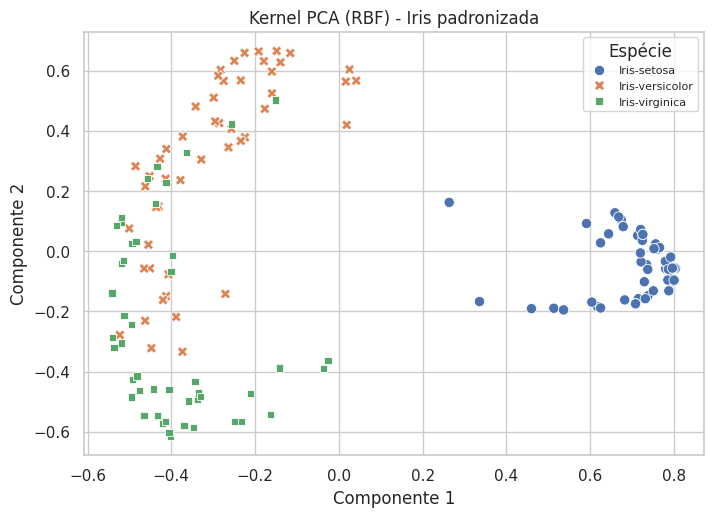

In [15]:
kpca = KernelPCA(n_components=2, kernel="rbf", gamma=GAMMA_KERNEL, eigen_solver="dense")
Z_kpca = kpca.fit_transform(X)
print("Autovalores do kernel centralizado:", np.round(kpca.eigenvalues_, 4))
print("Parâmetros:", kpca.get_params())
trust["Kernel PCA"] = trustworthiness(X, Z_kpca, n_neighbors=10)
scatter2d(Z_kpca, "Kernel PCA (RBF) - Iris padronizada")

### 6.3 t-SNE

Divergência KL final: 0.15848934650421143
Iterações: 999 | taxa de aprendizado efetiva: 50.0


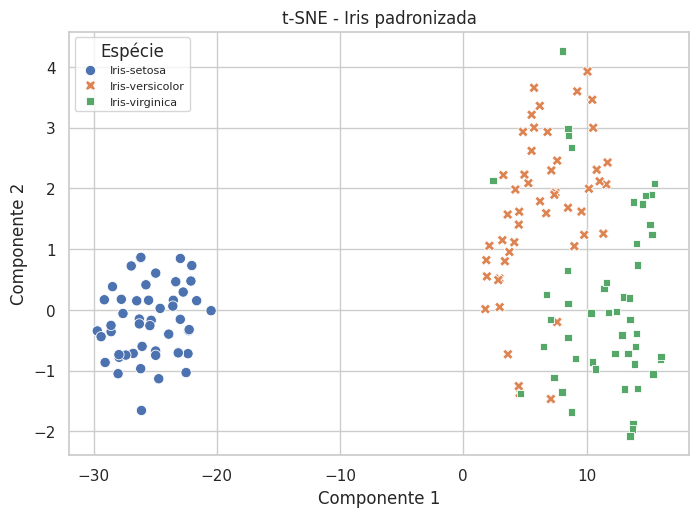

In [16]:
tsne = TSNE(n_components=2, perplexity=PERPLEXIDADE, learning_rate="auto", init="pca",
            max_iter=1000, random_state=SEED_Q2)
Z_tsne = tsne.fit_transform(X)
print("Divergência KL final:", tsne.kl_divergence_)
print("Iterações:", tsne.n_iter_, "| taxa de aprendizado efetiva:", tsne.learning_rate_)
trust["t-SNE"] = trustworthiness(X, Z_tsne, n_neighbors=10)
scatter2d(Z_tsne, "t-SNE - Iris padronizada")

### 6.4 UMAP

Parâmetros: {'n_neighbors': 15, 'min_dist': 0.1, 'metric': 'euclidean'}


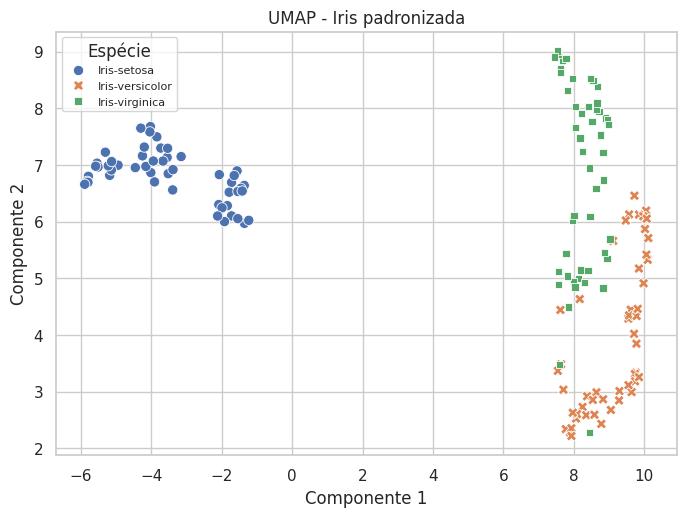

In [17]:
umap = UMAP(n_components=2, n_neighbors=VIZINHOS_UMAP, min_dist=MIN_DIST_UMAP,
            metric="euclidean", random_state=SEED_Q2, n_jobs=1)
Z_umap = umap.fit_transform(X)
print("Parâmetros:", dict(n_neighbors=VIZINHOS_UMAP, min_dist=MIN_DIST_UMAP, metric="euclidean"))
trust["UMAP"] = trustworthiness(X, Z_umap, n_neighbors=10)
scatter2d(Z_umap, "UMAP - Iris padronizada")

### 6.5 Comparação das técnicas

In [18]:
display(pd.Series(trust, name="Trustworthiness (10 vizinhos)").round(4).to_frame())

,Trustworthiness (10 vizinhos)
PCA,0.9782
Kernel PCA,0.9322
t-SNE,0.9890
UMAP,0.9783


## 7. Tunagem do DBSCAN e do Kernel Fuzzy (opcional)
As configurações são comparadas por silhueta, número de grupos e ruído. O ARI não entra na escolha, para não usar o rótulo verdadeiro na hora de definir hiperparâmetros.

In [19]:
from itertools import product
from sklearn.neighbors import NearestNeighbors

# distância típica até o 5º vizinho, usada como referência para o eps relativo
ref = float(np.median(NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)[0][:, -1]))

confs = [("eps_fixo", e, ms) for e, ms in product([0.4, 0.6, 0.8, 1.0], [3, 5, 10])]
confs += [("eps_relativo", ref * f, ms) for f, ms in product([0.75, 1.0, 1.5, 2.0], [3, 5, 10])]

lin = []
for regra, eps, ms in confs:
    r = dbscan(X, eps, ms)
    lin.append({"regra": regra, "eps": round(eps, 3), "min_samples": ms,
                "silhueta": calcular_silhueta(X, r.rotulos, ignorar_ruido=True),
                "grupos": len(set(r.rotulos) - {-1}), "ruido": r.ruido})
print("Grade DBSCAN:")
display(pd.DataFrame(lin).round(4))

lin = []
for g, k in product([0.05, 0.25, 1.0], range(1, 6)):
    cands = [_fuzzy(X, k, s, gamma=g) for s in range(42, 52)]
    melhor = min(cands, key=lambda r: r.objetivo)
    lin.append({"gamma": g, "k": k, "objetivo": melhor.objetivo,
                "silhueta": calcular_silhueta(X, melhor.rotulos)})
print("Grade Kernel Fuzzy (gamma x k):")
display(pd.DataFrame(lin).round(4))

Grade DBSCAN:


,regra,eps,min_samples,silhueta,grupos,ruido
0,eps_fixo,0.400,3,0.4177,10,39
1,eps_fixo,0.400,5,0.4853,6,66
2,eps_fixo,0.400,10,0.5303,2,118
3,eps_fixo,0.600,3,0.3449,4,9
4,eps_fixo,0.600,5,0.6405,2,26
5,eps_fixo,0.600,10,0.6482,2,35
6,eps_fixo,0.800,3,0.5963,2,4
7,eps_fixo,0.800,5,0.5963,2,4
8,eps_fixo,0.800,10,0.6067,2,8
9,eps_fixo,1.000,3,0.5851,2,1


Grade Kernel Fuzzy (gamma x k):


,gamma,k,objetivo,silhueta
0,0.05,1,52.0379,NaN
1,0.05,2,16.2229,0.5802
2,0.05,3,9.1734,0.4574
3,0.05,4,6.7338,0.3985
4,0.05,5,4.9334,0.3315
5,0.25,1,158.6132,NaN
6,0.25,2,55.1276,0.5802
7,0.25,3,32.7858,0.4574
8,0.25,4,23.9689,0.3941
9,0.25,5,17.9930,0.3285
